# Customer Churn End-to-End ML Project

> **Goal:** Predict whether a telecom customer will churn (leave the company)  
> **Dataset:** `data/data_23.csv` – ~7,111 rows × 21 columns  
> **Pipeline:** Data Cleaning → EDA → Feature Engineering → Correlation Analysis → Model Building → Evaluation → Model Selection → Deployment

---

In [1]:
# ── Standard imports ─────────────────────────────────────────────────────────
import sys, os, json, time, warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import joblib
import sklearn

# ── Make src/ importable (notebook is in notebooks/, project root is one level up)
PROJECT_ROOT = Path('.').resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import *
from src.data_cleaning import *
from src.feature_engineering import *

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_columns', 30)

print('Python:', sys.version[:6], '| sklearn:', sklearn.__version__)
print('Project root:', PROJECT_ROOT)

Python: 3.11.7 | sklearn: 1.2.2
Project root: C:\Users\talas\Downloads\churn_ml_project


---
## Section 1: Data Understanding

In [2]:
# Load the raw dataset
df_raw = load_data(str(PROJECT_ROOT / 'data' / 'data_23.csv'))
print(f'Shape: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns')
df_raw.head()

Shape: 7111 rows × 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1.0,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34.0,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2.0,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45.0,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2.0,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Data types and basic info
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7111 entries, 0 to 7110
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7111 non-null   object 
 1   gender            7111 non-null   object 
 2   SeniorCitizen     7111 non-null   int64  
 3   Partner           7111 non-null   object 
 4   Dependents        7104 non-null   object 
 5   tenure            7104 non-null   float64
 6   PhoneService      7098 non-null   object 
 7   MultipleLines     7098 non-null   object 
 8   InternetService   7094 non-null   object 
 9   OnlineSecurity    7095 non-null   object 
 10  OnlineBackup      7102 non-null   object 
 11  DeviceProtection  7091 non-null   object 
 12  TechSupport       7084 non-null   object 
 13  StreamingTV       7084 non-null   object 
 14  StreamingMovies   7084 non-null   object 
 15  Contract          7082 non-null   object 
 16  PaperlessBilling  7095 non-null   object 


In [4]:
# Identify numeric vs categorical columns
num_cols = df_raw.select_dtypes(include='number').columns.tolist()
cat_cols = df_raw.select_dtypes(include='object').columns.tolist()

print('NUMERIC columns:', num_cols)
print()
print('CATEGORICAL columns:', cat_cols)
print()
print('NOTE: SeniorCitizen is stored as 0/1 (numeric) but it means')
print('      "Is this customer a senior citizen?" → it is CATEGORICAL in meaning.')
print('NOTE: TotalCharges is stored as object (text) but should be numeric.')
print('NOTE: Churn is our TARGET column.')

NUMERIC columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges']

CATEGORICAL columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']

NOTE: SeniorCitizen is stored as 0/1 (numeric) but it means
      "Is this customer a senior citizen?" → it is CATEGORICAL in meaning.
NOTE: TotalCharges is stored as object (text) but should be numeric.
NOTE: Churn is our TARGET column.


In [5]:
# Descriptive statistics – numeric
df_raw.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7111.00,7104.00,7093.00
mean,0.16,32.35,64.83
std,0.37,24.56,30.08
min,0.00,0.00,18.25
25%,0.00,9.00,35.65
50%,0.00,29.00,70.35
75%,0.00,55.00,89.90
max,1.00,72.00,118.75


In [6]:
# Descriptive statistics – categorical
df_raw.describe(include='object')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7111,7111,7111,7104,7098,7098,7094,7095,7102,7091,7084,7084,7084,7082,7095,7095,7039,7039
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6511,2
top,5110-CHOPY,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,2,3589,3677,4974,6412,3414,3120,3526,3111,3119,3499,2826,2809,3896,4203,2383,11,5166


Churn distribution:
       Count     %
Churn             
No      5166  72.6
Yes     1873  26.3
NaN       72   1.0


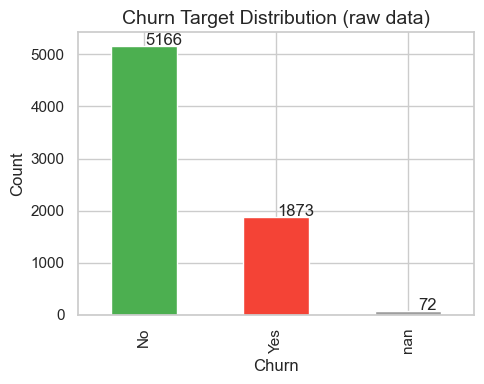

In [7]:
# Target class distribution
churn_counts = df_raw['Churn'].value_counts(dropna=False)
churn_pct    = df_raw['Churn'].value_counts(dropna=False, normalize=True) * 100
print('Churn distribution:')
print(pd.concat([churn_counts, churn_pct.round(1)], axis=1, keys=['Count', '%']))

fig, ax = plt.subplots(figsize=(5, 4))
churn_counts.plot(kind='bar', ax=ax, color=['#4CAF50', '#F44336', '#9E9E9E'], edgecolor='white')
ax.set_title('Churn Target Distribution (raw data)', fontsize=14)
ax.set_xlabel('Churn'); ax.set_ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + 0.4, p.get_height() + 20), ha='center')
plt.tight_layout(); plt.show()

**Observations – Target Distribution:**
- The dataset has 7,111 rows, of which **72 rows have a missing Churn label** (cannot be used for training).
- Among labelled rows: ~**5,163 No (73%)** and ~**1,869 Yes (27%)**.
- This is a **class imbalance** – the model will see roughly 2.7× more non-churners than churners. We must handle this with `class_weight='balanced'` and focus on Recall/F1 rather than just Accuracy.

---
## Section 2: Data Cleaning
> Every step below has a **WHY** explaining why it is necessary.

Missing value report:
                  missing_count  missing_percent
Churn                        72             1.01
TotalCharges                 72             1.01
Contract                     29             0.41
StreamingTV                  27             0.38
StreamingMovies              27             0.38
TechSupport                  27             0.38
DeviceProtection             20             0.28
MonthlyCharges               18             0.25
InternetService              17             0.24
OnlineSecurity               16             0.23
PaperlessBilling             16             0.23
PaymentMethod                16             0.23
MultipleLines                13             0.18
PhoneService                 13             0.18
OnlineBackup                  9             0.13
tenure                        7             0.10
Dependents                    7             0.10


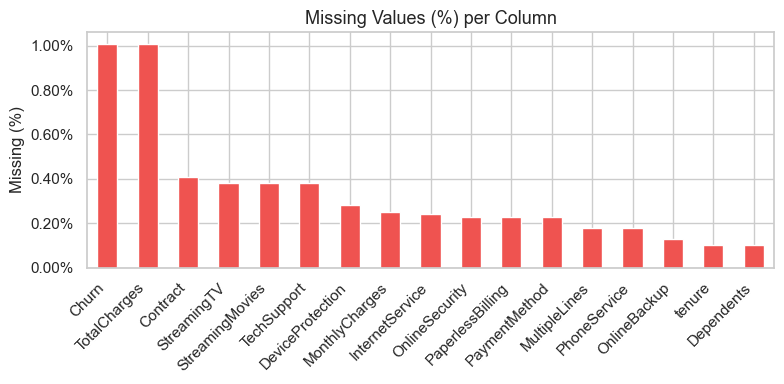

In [8]:
# ── 2.1 Missing value analysis ───────────────────────────────────────────────
# WHY: We need to know which columns have missing data and how much
#      before we can decide how to fix them.
mv_report = missing_value_report(df_raw)
print('Missing value report:')
print(mv_report)

fig, ax = plt.subplots(figsize=(8, 4))
mv_report['missing_percent'].plot(kind='bar', ax=ax, color='#EF5350', edgecolor='white')
ax.set_title('Missing Values (%) per Column', fontsize=13)
ax.set_ylabel('Missing (%)')
ax.set_xlabel('')
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()

**Observations – Missing Values:**  
- `Churn` has 72 missing rows (~1%). **These will be dropped** because a supervised model cannot learn from a row that has no label.
- `TotalCharges` has ~83 unparseable entries (stored as blank strings). They will be converted to NaN and imputed with the median.
- Other columns (Contract, TechSupport, etc.) have small amounts of missing data that will be mode-imputed inside the sklearn Pipeline.

In [9]:
# ── 2.2 Drop rows with missing Churn target ──────────────────────────────────
# WHY: A supervised learning model needs a label for every training row.
#      If the label is missing we cannot know what the model should predict,
#      so keeping those rows would corrupt the training signal.
df = drop_missing_target(df_raw, 'Churn')
print(f'Rows before: {len(df_raw)} | After dropping missing Churn: {len(df)}')

Rows before: 7111 | After dropping missing Churn: 7039


In [10]:
# ── 2.3 Fix data types ───────────────────────────────────────────────────────
# See docstring in data_cleaning.py for WHY each conversion is done.
df = fix_data_types(df)
print('After type fixes:')
print(df.dtypes[['TotalCharges', 'tenure', 'SeniorCitizen']])

After type fixes:
TotalCharges     float64
tenure             Int64
SeniorCitizen     object
dtype: object


In [11]:
# ── 2.4 Standardise categorical values ───────────────────────────────────────
# WHY: Strip whitespace and unify case so 'yes ', ' Yes', 'YES' are all 'Yes'.
#      'No internet service' and 'No phone service' are valid categories, not errors.
df = clean_categorical_values(df)

# Show unique values per categorical column to verify
for col in df.select_dtypes('object').columns:
    print(f'  {col}: {sorted(df[col].dropna().unique())}')

  customerID: ['0002-Orfbo', '0003-Mknfe', '0004-Tlhlj', '0011-Igkff', '0013-Exchz', '0013-Mhzwf', '0013-Smeoe', '0014-Bmaqu', '0015-Uocoj', '0016-Qljis', '0017-Dinoc', '0017-Iudmw', '0018-Nyrou', '0019-Efaep', '0019-Gfntw', '0020-Inwck', '0020-Jdnxp', '0021-Ikxgc', '0023-Hghwl', '0023-Uyupn', '0023-Xuopt', '0027-Kwykw', '0030-Fnxpp', '0031-Pvlzi', '0032-Pgels', '0036-Ihmot', '0040-Halcw', '0042-Jvwoj', '0042-Rlhyp', '0048-Lumls', '0048-Pihnl', '0052-Dckon', '0052-Ynyot', '0056-Epfbg', '0057-Qbuqh', '0058-Evzwm', '0060-Fualy', '0064-Sudog', '0064-Yijgf', '0067-Dkwbl', '0068-Figtf', '0071-Ndafp', '0074-Hdkdg', '0076-Lveps', '0078-Xzmht', '0080-Emyvy', '0080-Orozo', '0082-Ldzue', '0082-Oqiqy', '0083-Pivik', '0089-Iiqko', '0093-Exyql', '0093-Xwzfy', '0094-Oifmo', '0096-Bxers', '0096-Fcpuf', '0098-Bowso', '0100-Duvfc', '0103-Csitq', '0104-Ppxdv', '0106-Ghrqr', '0106-Ugrdo', '0107-Weslm', '0107-Yhina', '0111-Klbqg', '0112-Qawrz', '0112-Qwpnc', '0114-Igabw', '0114-Pegzz', '0114-Rsrrw', '0115

In [12]:
# ── 2.5 Duplicate detection and removal ──────────────────────────────────────
# WHY: Duplicate rows add no new information and can bias the model toward
#      patterns seen in repeated rows.
full_dups = df.duplicated()
print(f'Fully duplicated rows: {full_dups.sum()}')
if full_dups.sum() > 0:
    print('Sample duplicates:')
    print(df[full_dups].head(3))

id_dups = df.duplicated(subset=['customerID'])
print(f'\nDuplicated customerIDs (after removing full dups): {id_dups.sum()}')

df = remove_duplicates(df)
print(f'\nRows after de-duplication: {len(df)}')

Fully duplicated rows: 20
Sample duplicates:
      customerID  gender SeniorCitizen Partner Dependents  tenure  \
7043  5110-Chopy  Female            No      No         No      60   
7044  5445-Utodq  Female            No     Yes         No       7   
7045  4425-Owhwb  Female            No      No         No      20   

     PhoneService     MultipleLines InternetService       OnlineSecurity  \
7043           No  No Phone Service             Dsl                  Yes   
7044          Yes                No     Fiber Optic                   No   
7045          Yes                No              No  No Internet Service   

             OnlineBackup     DeviceProtection          TechSupport  \
7043                   No                  Yes                   No   
7044                   No                   No                   No   
7045  No Internet Service  No Internet Service  No Internet Service   

              StreamingTV      StreamingMovies        Contract  \
7043                  

                    Q1       Q3      IQR  Lower fence  Upper fence  N outliers
tenure            9.00    55.00    46.00       -60.00       124.00         0.0
MonthlyCharges   35.58    89.88    54.30       -45.87       171.32         0.0
TotalCharges    401.45  3796.91  3395.46     -4691.74      8890.11         0.0


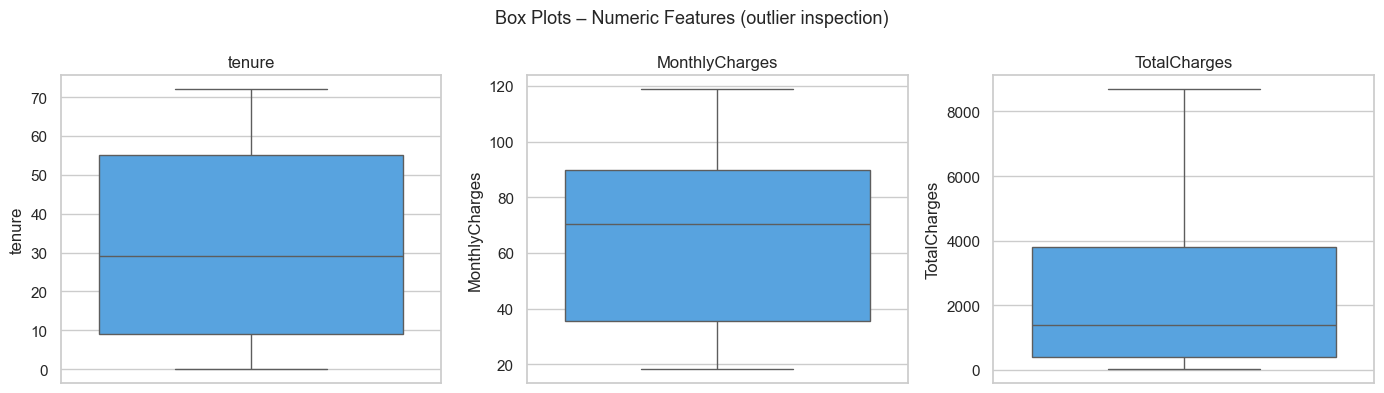

In [13]:
# ── 2.6 Outlier detection ────────────────────────────────────────────────────
# WHY: Extreme values can distort the model's learned weights (especially
#      Logistic Regression) and cause the scaler to shift its mean/std.
#      We use the IQR rule (anything outside Q1 - 1.5*IQR or Q3 + 1.5*IQR)
#      to flag outliers, then decide whether to keep or cap them.

def iqr_outlier_summary(series: pd.Series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((series < lower) | (series > upper)).sum()
    return pd.Series({'Q1': q1, 'Q3': q3, 'IQR': iqr,
                      'Lower fence': lower, 'Upper fence': upper,
                      'N outliers': n_out})

num_df = df[['tenure', 'MonthlyCharges', 'TotalCharges']].apply(pd.to_numeric, errors='coerce')
print(num_df.apply(iqr_outlier_summary).T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.boxplot(data=df, y=pd.to_numeric(df[col], errors='coerce'), ax=ax, color='#42A5F5')
    ax.set_title(col)
plt.suptitle('Box Plots – Numeric Features (outlier inspection)', fontsize=13)
plt.tight_layout(); plt.show()

**Observations – Outliers:**  
- `tenure`: ranges 0–72 months (designed that way) — no true outliers.
- `MonthlyCharges`: IQR shows a wide but valid range ($18–$118). High values correspond to customers with many services. We **keep** all values.
- `TotalCharges`: naturally correlated with tenure × MonthlyCharges — high values are legitimate long-tenure customers. We **keep** all values.
- **Decision:** We do **not** cap or remove any outliers. The extreme values are all business-valid. Removing them would lose important high-value customer information.

In [14]:
# ── 2.7 Invalid values ───────────────────────────────────────────────────────
df = fix_invalid_numeric_values(df)

# Check tenure=0 with TotalCharges present
zero_tenure = df[pd.to_numeric(df['tenure'], errors='coerce') == 0]
print(f'Rows with tenure=0: {len(zero_tenure)}')
print(zero_tenure[['tenure','MonthlyCharges','TotalCharges']].head())

Rows with tenure=0: 11
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN


In [15]:
# ── 2.8 Drop customerID ──────────────────────────────────────────────────────
# WHY: customerID is a unique identifier assigned by the billing system.
#      It has no relationship to churn behaviour. Including it would only
#      confuse the model and add no predictive value.
df = drop_unnecessary_columns(df, ['customerID'])
print('Columns after dropping customerID:', df.columns.tolist())

Columns after dropping customerID: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [16]:
# ── 2.9 Leakage detection ────────────────────────────────────────────────────
# WHY: Data leakage means the model accidentally learns from information
#      that would not be available at prediction time, giving overly
#      optimistic test results that collapse in production.

# TotalCharges ≈ tenure × MonthlyCharges (check correlation)
tenure_n = pd.to_numeric(df['tenure'], errors='coerce')
monthly_n = pd.to_numeric(df['MonthlyCharges'], errors='coerce')
total_n   = pd.to_numeric(df['TotalCharges'], errors='coerce')
computed  = tenure_n * monthly_n

valid_mask = computed.notna() & total_n.notna()
corr_val = computed[valid_mask].corr(total_n[valid_mask])
print(f'Correlation between tenure×MonthlyCharges and TotalCharges: {corr_val:.4f}')
print()
print('Leakage conclusions:')
print('  1. TotalCharges is derived from tenure and MonthlyCharges (high correlation).')
print('     This is REDUNDANCY, not leakage – all three are available at prediction time.')
print('  2. No feature is derived from the target (Churn).')
print('  3. Imputers/scalers/encoders will be fit ONLY on the training split (inside Pipeline).')
print('  4. The training/test split happens BEFORE any fitting – no test data leaks into training.')

Correlation between tenure×MonthlyCharges and TotalCharges: 0.9996

Leakage conclusions:
  1. TotalCharges is derived from tenure and MonthlyCharges (high correlation).
     This is REDUNDANCY, not leakage – all three are available at prediction time.
  2. No feature is derived from the target (Churn).
  3. Imputers/scalers/encoders will be fit ONLY on the training split (inside Pipeline).
  4. The training/test split happens BEFORE any fitting – no test data leaks into training.


In [17]:
# ── 2.10 Missing value summary after cleaning ─────────────────────────────────
mv_after = missing_value_report(df)
print('Remaining missing values after cleaning:')
if len(mv_after) == 0:
    print('  None in most columns. TotalCharges NaNs will be imputed inside the Pipeline.')
else:
    print(mv_after)
print(f'\nFinal clean shape: {df.shape}')

Remaining missing values after cleaning:
                  missing_count  missing_percent
TechSupport                  24             0.34
StreamingTV                  24             0.34
StreamingMovies              21             0.30
DeviceProtection             20             0.28
InternetService              17             0.24
OnlineSecurity               16             0.23
Contract                     16             0.23
PhoneService                 13             0.19
MultipleLines                13             0.19
TotalCharges                 11             0.16
OnlineBackup                  9             0.13
Dependents                    7             0.10
tenure                        7             0.10
PaperlessBilling              3             0.04
PaymentMethod                 3             0.04

Final clean shape: (7019, 20)


**Imputation strategy (inside sklearn Pipeline):**  
- **Numeric columns** → `SimpleImputer(strategy='median')`: the median is robust to outliers, unlike the mean.
- **Categorical columns** → `SimpleImputer(strategy='most_frequent')`: the mode is the safest default for categories.
- Both imputers are fitted **only on training data** (inside the Pipeline), so test data never influences the imputed values.

---
## Section 3: EDA (Exploratory Data Analysis)
> An "Observations" markdown cell follows each chart.

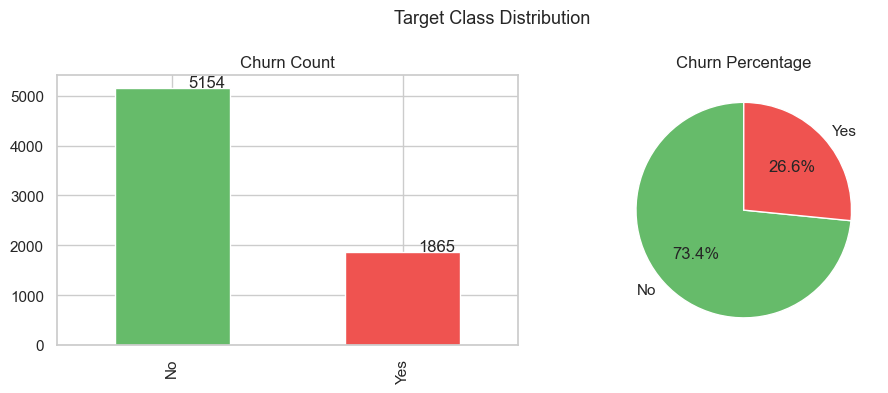

In [18]:
# Add Churn_int for correlation use
df['Churn_int'] = (df['Churn'] == 'Yes').astype(int)

# Numeric columns for EDA
eda_num = ['tenure', 'MonthlyCharges', 'TotalCharges']
for col in eda_num:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# ── 3.1 Target distribution ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
churn_ct = df['Churn'].value_counts()
churn_ct.plot(kind='bar', ax=axes[0], color=['#66BB6A','#EF5350'], edgecolor='white')
axes[0].set_title('Churn Count'); axes[0].set_xlabel('')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x()+0.4, p.get_height()+20), ha='center')

churn_ct.plot(kind='pie', ax=axes[1], autopct='%1.1f%%', colors=['#66BB6A','#EF5350'], startangle=90)
axes[1].set_ylabel(''); axes[1].set_title('Churn Percentage')
plt.suptitle('Target Class Distribution', fontsize=13)
plt.tight_layout(); plt.show()

**Observations:** ~73% of customers did NOT churn, ~27% did. This imbalance means accuracy alone is a misleading metric.

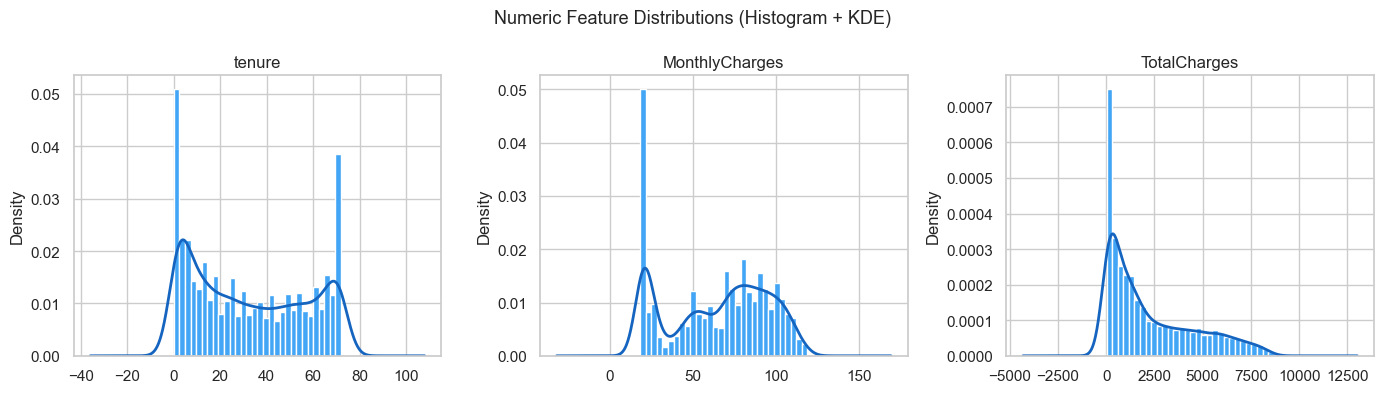

In [19]:
# ── 3.2 Histograms + KDE for numeric features ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, eda_num):
    df[col].dropna().plot(kind='hist', bins=30, ax=ax, color='#42A5F5', edgecolor='white', density=True)
    df[col].dropna().plot(kind='kde', ax=ax, color='#1565C0', linewidth=2)
    ax.set_title(col)
plt.suptitle('Numeric Feature Distributions (Histogram + KDE)', fontsize=13)
plt.tight_layout(); plt.show()

**Observations:**  
- `tenure`: bimodal – many customers are new (0-12 months) OR long-tenured (60-72 months). Churn risk is highest for new customers.
- `MonthlyCharges`: right-skewed, with a cluster at low values and a long tail of high-spend customers.
- `TotalCharges`: right-skewed as expected (tenure × MonthlyCharges).

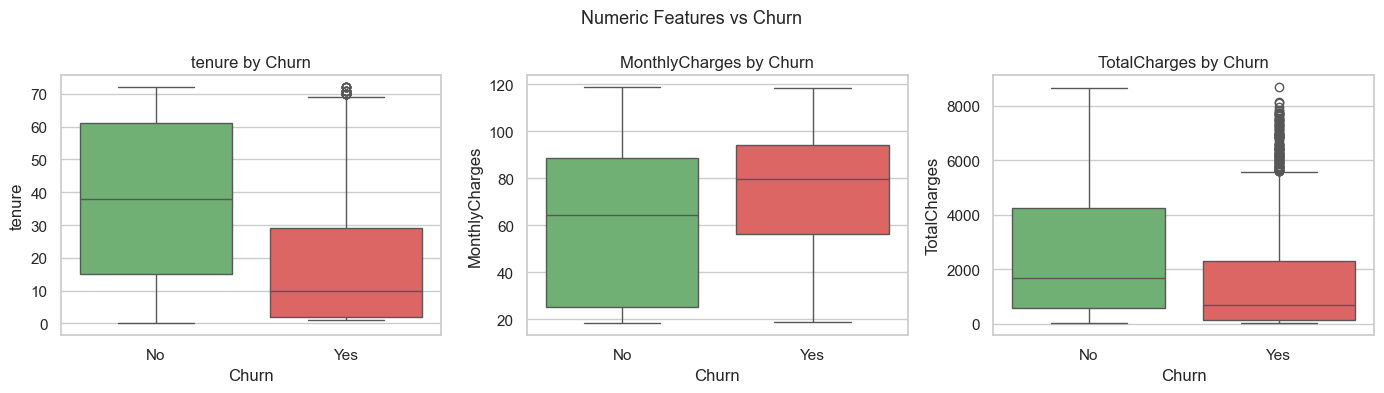

In [20]:
# ── 3.3 Box plots by Churn ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, eda_num):
    sns.boxplot(data=df, x='Churn', y=col, ax=ax, palette={'No':'#66BB6A','Yes':'#EF5350'})
    ax.set_title(f'{col} by Churn')
plt.suptitle('Numeric Features vs Churn', fontsize=13)
plt.tight_layout(); plt.show()

**Observations:**  
- `tenure`: Churners have **much shorter tenure** (median ~10 months vs ~38 months for stayers). This is the strongest numeric signal.
- `MonthlyCharges`: Churners pay **more per month** (median ~$79 vs $65 for stayers).
- `TotalCharges`: Churners have lower total charges (they haven't been customers long enough).

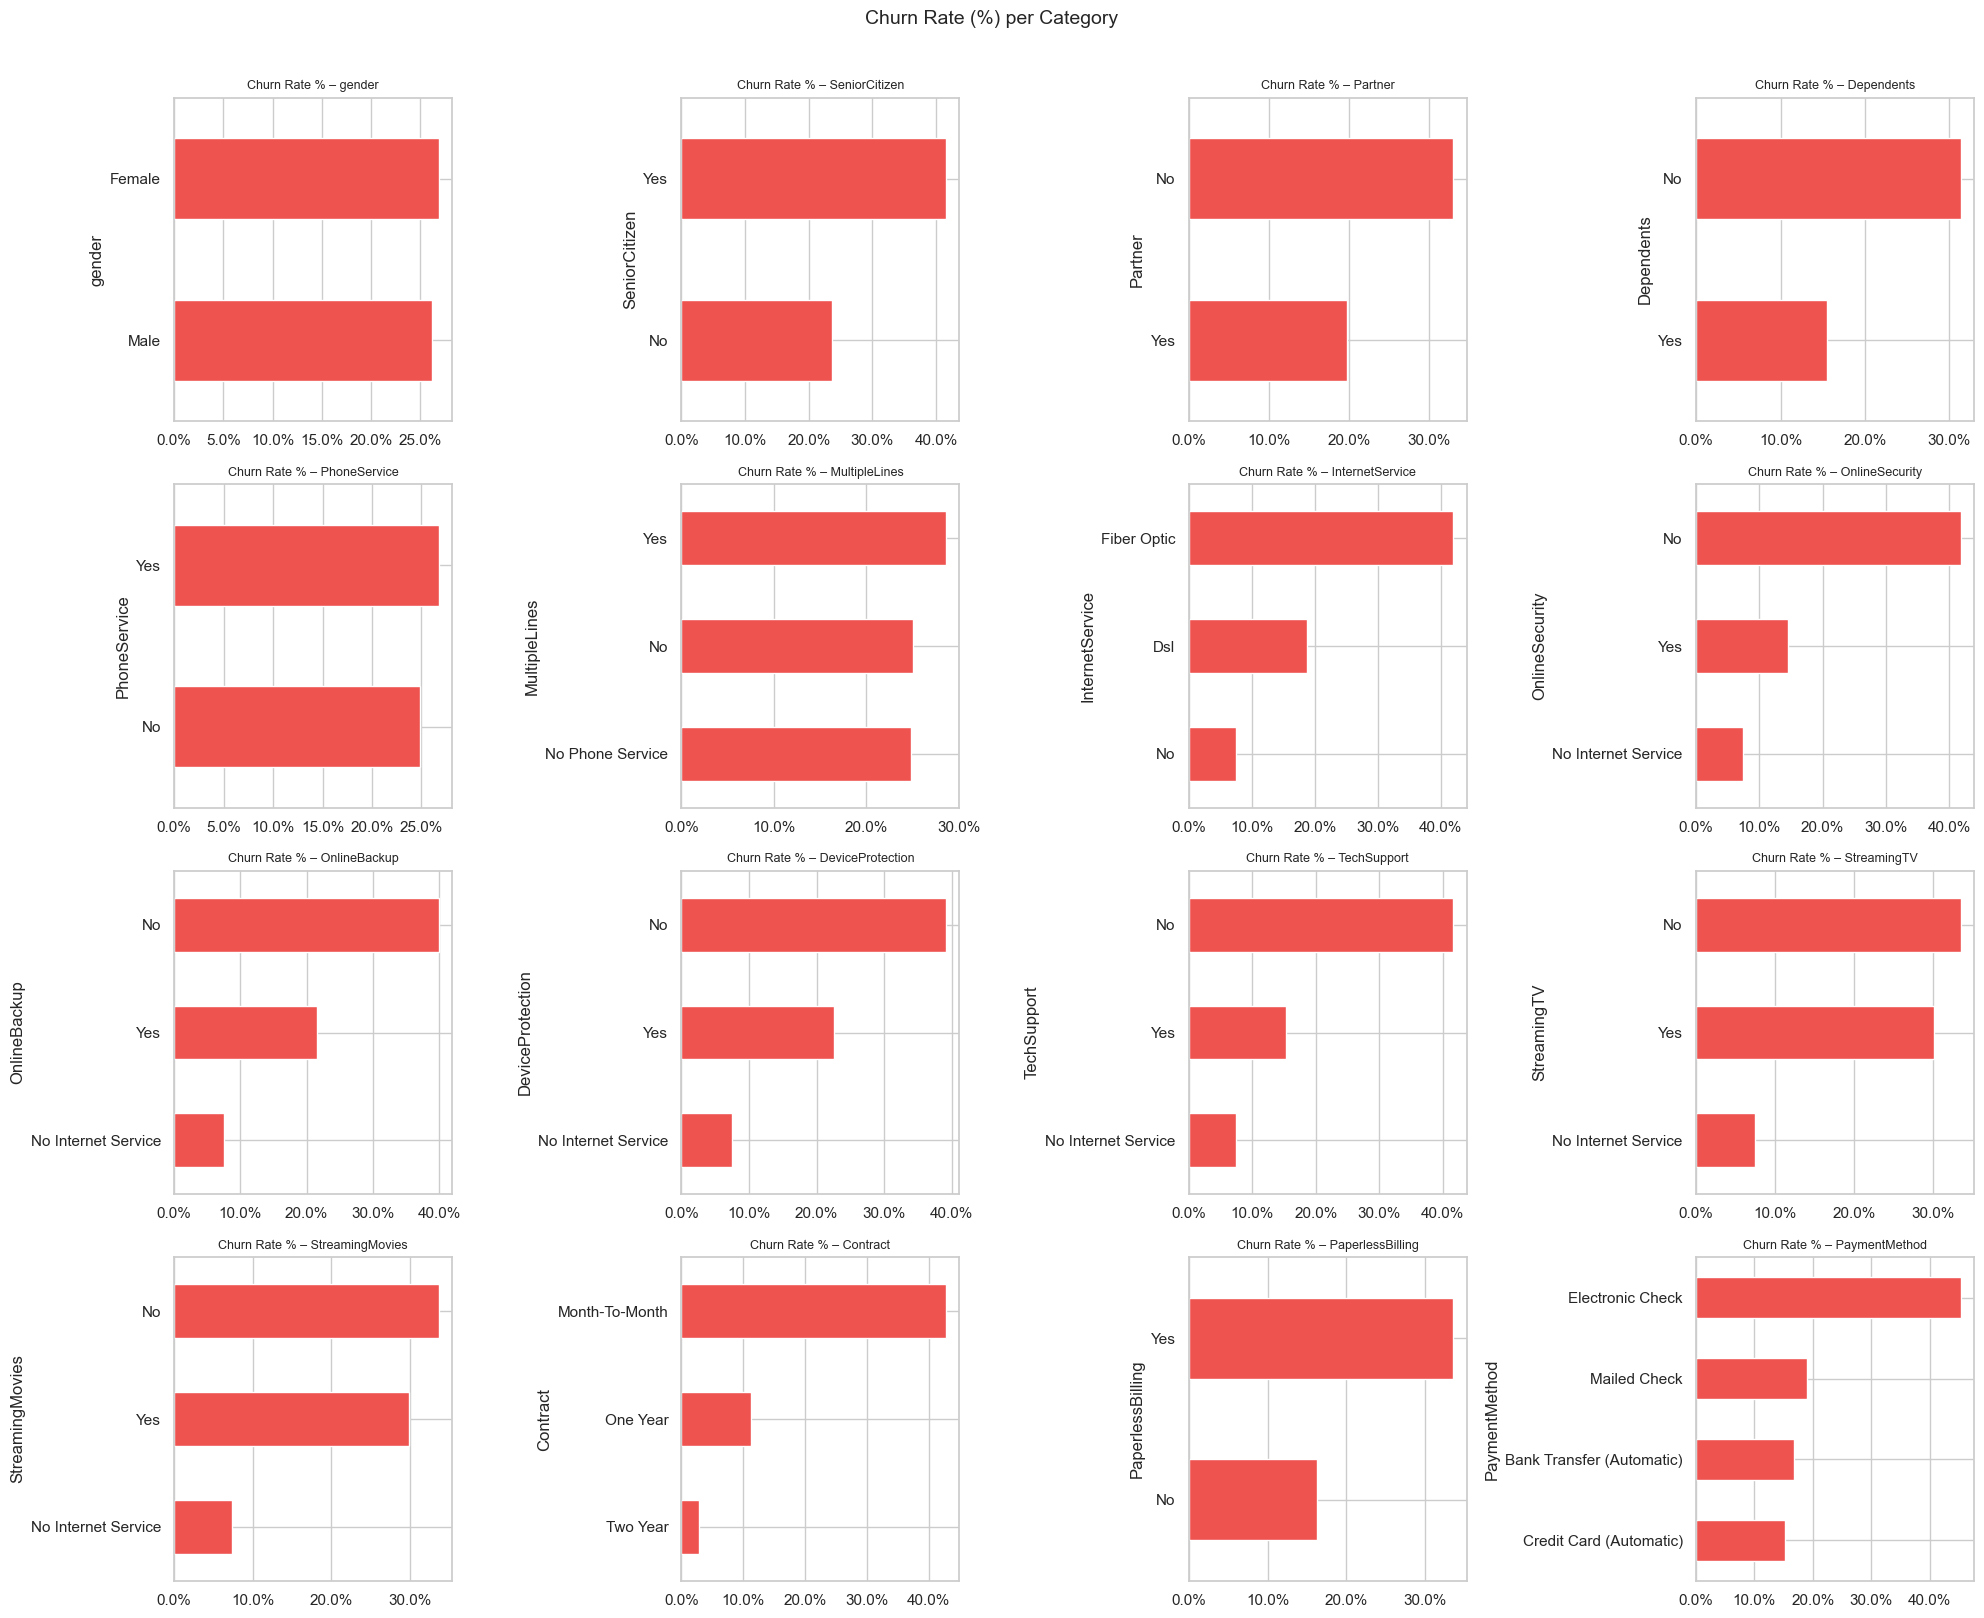

In [21]:
# ── 3.4 Categorical feature count plots + churn rate ─────────────────────────
cat_features = ['gender','SeniorCitizen','Partner','Dependents','PhoneService',
                'MultipleLines','InternetService','OnlineSecurity','OnlineBackup',
                'DeviceProtection','TechSupport','StreamingTV','StreamingMovies',
                'Contract','PaperlessBilling','PaymentMethod']

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()
for i, col in enumerate(cat_features):
    churn_rate = df.groupby(col)['Churn_int'].mean().sort_values() * 100
    churn_rate.plot(kind='barh', ax=axes[i], color='#EF5350', edgecolor='white')
    axes[i].set_title(f'Churn Rate % – {col}', fontsize=9)
    axes[i].xaxis.set_major_formatter(mticker.PercentFormatter())
    axes[i].set_xlabel('')
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle('Churn Rate (%) per Category', fontsize=14, y=1.01)
plt.tight_layout(); plt.show()

**Observations – Key Business Insights:**  
1. **Contract type:** Month-to-month customers churn at ~43%, vs ~11% (1-year) and ~3% (2-year). The **strongest predictor**.
2. **Internet service:** Fiber optic customers churn at ~42% vs DSL ~19% vs No Internet ~7%.
3. **Online Security / Tech Support:** Customers without these add-ons churn significantly more.
4. **Payment method:** Electronic check customers churn at ~45% vs ~17% for auto-pay methods.
5. **Paperless billing:** Paperless billing customers churn more (~34%) than paper billing (~17%).
6. **Senior Citizens:** Higher churn rate (~41%) than non-seniors (~24%).
7. **Partner/Dependents:** Customers without partners or dependents churn more – they have less "switching friction".

---
## Section 4: Correlation Analysis

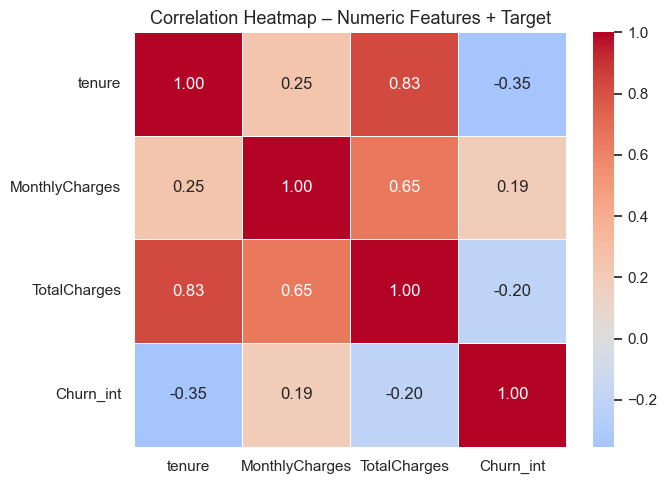

In [22]:
# Encode categorical columns for correlation
from sklearn.preprocessing import LabelEncoder

df_enc = df.copy()
for col in df_enc.select_dtypes('object').columns:
    if col != 'Churn':
        df_enc[col] = LabelEncoder().fit_transform(df_enc[col].astype(str))

corr_cols = eda_num + ['Churn_int']
corr_matrix = df_enc[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', ax=ax,
            linewidths=0.5, center=0)
ax.set_title('Correlation Heatmap – Numeric Features + Target', fontsize=13)
plt.tight_layout(); plt.show()

In [23]:
# Full correlation matrix (all encoded features)
corr_full = df_enc.drop(columns=['Churn']).corr()
print('Highly correlated pairs (|r| > 0.8):')
high_corr = []
for i in range(len(corr_full.columns)):
    for j in range(i+1, len(corr_full.columns)):
        r = corr_full.iloc[i,j]
        if abs(r) > 0.8:
            high_corr.append((corr_full.columns[i], corr_full.columns[j], round(r,4)))
            print(f'  {corr_full.columns[i]} ↔ {corr_full.columns[j]}: r={r:.4f}')
if not high_corr:
    print('  (none found)')

Highly correlated pairs (|r| > 0.8):
  tenure ↔ TotalCharges: r=0.8261


In [24]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
# Simple VIF check on numeric features
try:
    import statsmodels
    vif_data = df_enc[corr_cols[:-1]].dropna().astype(float)  # float required by statsmodels
    vif_vals = [variance_inflation_factor(vif_data.values, i) for i in range(vif_data.shape[1])]
    vif_df = pd.DataFrame({'Feature': vif_data.columns, 'VIF': [round(v,2) for v in vif_vals]})
    print('VIF (Variance Inflation Factor):')
    print(vif_df)
    print()
    print('VIF > 5 indicates multicollinearity. TotalCharges and tenure are correlated')
    print('(TotalCharges ≈ tenure × MonthlyCharges).')
    print('We KEEP TotalCharges because it provides useful magnitude information')
    print('and the Pipeline handles it well. Logistic Regression benefits from')
    print('StandardScaler which reduces the effect of multicollinearity.')
except ImportError:
    print('statsmodels not available – install with: pip install statsmodels')
    print('VIF check skipped.')

VIF (Variance Inflation Factor):
          Feature   VIF
0          tenure  6.34
1  MonthlyCharges  3.36
2    TotalCharges  8.08

VIF > 5 indicates multicollinearity. TotalCharges and tenure are correlated
(TotalCharges ≈ tenure × MonthlyCharges).
We KEEP TotalCharges because it provides useful magnitude information
and the Pipeline handles it well. Logistic Regression benefits from
StandardScaler which reduces the effect of multicollinearity.


**Observations – Correlation:**  
- `TotalCharges` and `tenure` are highly correlated (as expected, since TotalCharges ≈ tenure × MonthlyCharges).
- `tenure` has a **negative** correlation with Churn (longer tenure → less likely to churn).
- `MonthlyCharges` has a **positive** correlation with Churn.
- **Decision on TotalCharges:** We keep it. Although it is partially redundant with tenure, it still carries useful magnitude information about a customer's total investment. The Pipeline's StandardScaler reduces the practical impact of multicollinearity for Logistic Regression.

---
## Section 5: Feature Engineering

In [25]:
# Apply feature engineering using the reusable function from src/
# WHY: All features are created in src/feature_engineering.py so the SAME
# code runs in the notebook, in train.py, and in the backend API.
# This prevents train/serve skew.

df_feat = build_features_df(df.drop(columns=['Churn_int']))

print('New features added:')
new_cols = ['tenure_group','avg_monthly_spend','num_services',
            'has_internet','has_phone','auto_pay','is_monthly_fiber','tenure_x_monthly']
print(df_feat[new_cols].describe().round(2))

New features added:
       avg_monthly_spend  num_services  has_internet  has_phone  auto_pay  \
count             7001.0       7019.00       7019.00     7019.0   7019.00   
mean               59.11          2.03          0.78        0.9      0.43   
std                30.52          1.85          0.41        0.3      0.50   
min                 9.18          0.00          0.00        0.0      0.00   
25%                26.25          0.00          1.00        1.0      0.00   
50%                61.06          2.00          1.00        1.0      0.00   
75%                84.89          3.00          1.00        1.0      1.00   
max               118.97          6.00          1.00        1.0      1.00   

       is_monthly_fiber  tenure_x_monthly  
count           7019.00            7012.0  
mean               0.30           2279.08  
std                0.46           2265.59  
min                0.00               0.0  
25%                0.00             394.0  
50%                0.0

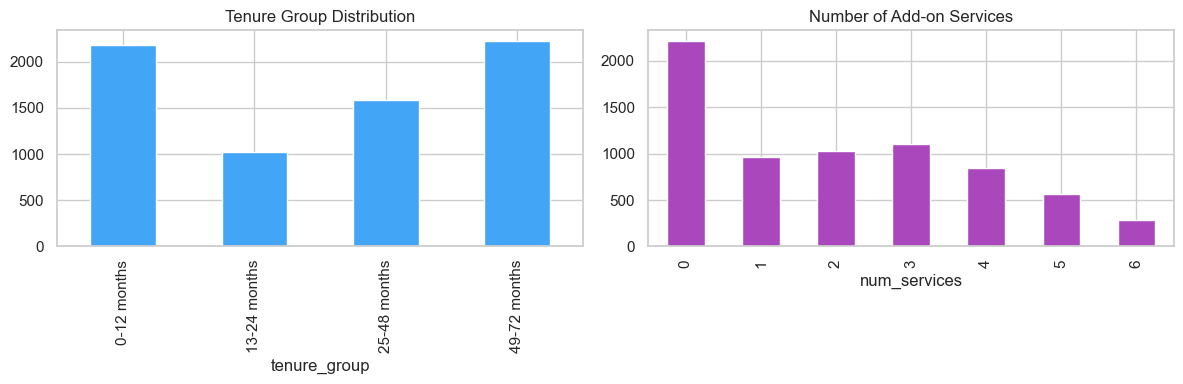


NOTE on date extraction:
The dataset has NO date/timestamp columns (only customerID, demographics,
service flags, billing info, and Churn). Date extraction is NOT applicable.


In [26]:
# Show tenure_group distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_feat['tenure_group'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='#42A5F5', edgecolor='white')
axes[0].set_title('Tenure Group Distribution')

# num_services distribution
df_feat['num_services'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='#AB47BC', edgecolor='white')
axes[1].set_title('Number of Add-on Services')
plt.tight_layout(); plt.show()

print('\nNOTE on date extraction:')
print('The dataset has NO date/timestamp columns (only customerID, demographics,')
print('service flags, billing info, and Churn). Date extraction is NOT applicable.')

In [27]:
# Encode target for modelling
y_all = encode_target(df['Churn'])
X_all = df_feat.drop(columns=['Churn'])
print(f'X shape: {X_all.shape} | y distribution: {y_all.value_counts().to_dict()}')

X shape: (7019, 27) | y distribution: {0: 5154, 1: 1865}


---
## Section 6: Feature Selection

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score, roc_auc_score, accuracy_score

sys.path.insert(0, str(PROJECT_ROOT))
from src.train import build_preprocessor, build_models, compute_metrics

# 80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=42, stratify=y_all
)
print(f'Train: {len(X_train)} | Test: {len(X_test)}')
print(f'Train churn rate: {y_train.mean():.2%} | Test churn rate: {y_test.mean():.2%}')

Train: 5615 | Test: 1404
Train churn rate: 26.57% | Test churn rate: 26.57%


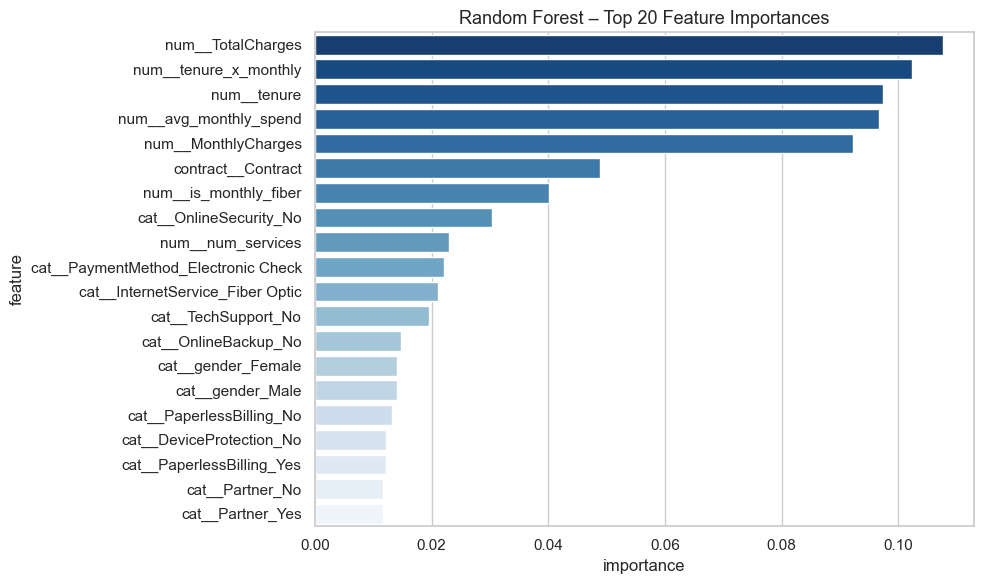

In [29]:
# ── 6a. Random Forest feature importance ─────────────────────────────────────
preprocessor = build_preprocessor(X_train)
rf_pipe = Pipeline([('pre', preprocessor), ('clf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))])
rf_pipe.fit(X_train, y_train)

# Get feature names from the fitted ColumnTransformer
try:
    feat_names = rf_pipe['pre'].get_feature_names_out()
except Exception:
    feat_names = [f'f{i}' for i in range(rf_pipe['clf'].n_features_in_)]

importances = rf_pipe['clf'].feature_importances_
fi_df = pd.DataFrame({'feature': feat_names, 'importance': importances})\
          .sort_values('importance', ascending=False).head(20)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=fi_df, x='importance', y='feature', ax=ax, palette='Blues_r')
ax.set_title('Random Forest – Top 20 Feature Importances', fontsize=13)
plt.tight_layout(); plt.show()

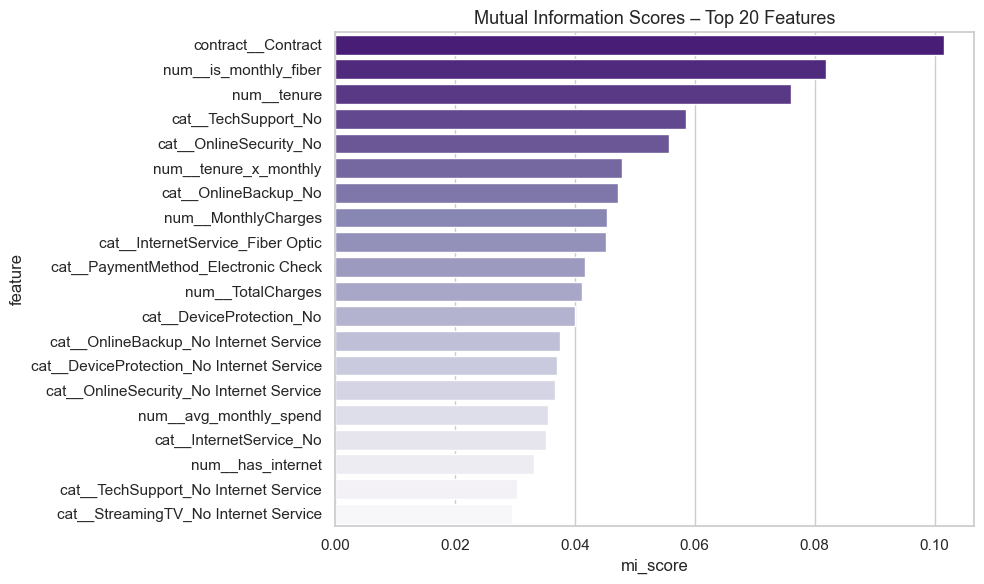

In [30]:
# ── 6b. Mutual information ───────────────────────────────────────────────────
X_train_pre = preprocessor.transform(X_train)
mi_scores = mutual_info_classif(X_train_pre, y_train, random_state=42)
mi_df = pd.DataFrame({'feature': feat_names, 'mi_score': mi_scores})\
          .sort_values('mi_score', ascending=False).head(20)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=mi_df, x='mi_score', y='feature', ax=ax, palette='Purples_r')
ax.set_title('Mutual Information Scores – Top 20 Features', fontsize=13)
plt.tight_layout(); plt.show()

In [31]:
# ── 6c. RFE with Logistic Regression ────────────────────────────────────────
lr = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
rfe = RFE(estimator=lr, n_features_to_select=15)
rfe.fit(X_train_pre, y_train)
rfe_selected = [f for f, s in zip(feat_names, rfe.support_) if s]
print(f'RFE selected {len(rfe_selected)} features:')
print(rfe_selected)

RFE selected 15 features:
['num__tenure', 'num__TotalCharges', 'num__avg_monthly_spend', 'num__has_internet', 'cat__SeniorCitizen_No', 'cat__MultipleLines_No', 'cat__InternetService_Dsl', 'cat__InternetService_Fiber Optic', 'cat__OnlineBackup_No Internet Service', 'cat__DeviceProtection_No Internet Service', 'cat__StreamingTV_Yes', 'cat__StreamingMovies_Yes', 'cat__PaperlessBilling_No', 'cat__PaymentMethod_Electronic Check', 'contract__Contract']


In [32]:
# ── 6d. SelectFromModel (Random Forest) ─────────────────────────────────────
sfm = SelectFromModel(rf_pipe['clf'], threshold='mean')
sfm.fit(X_train_pre, y_train)
sfm_selected = [f for f, s in zip(feat_names, sfm.get_support()) if s]
print(f'SelectFromModel selected {len(sfm_selected)} features:')
print(sfm_selected)

SelectFromModel selected 12 features:
['num__tenure', 'num__MonthlyCharges', 'num__TotalCharges', 'num__avg_monthly_spend', 'num__num_services', 'num__is_monthly_fiber', 'num__tenure_x_monthly', 'cat__InternetService_Fiber Optic', 'cat__OnlineSecurity_No', 'cat__TechSupport_No', 'cat__PaymentMethod_Electronic Check', 'contract__Contract']


In [33]:
# ── 6e. Before vs after feature selection comparison ─────────────────────────
# Compare: all features vs RFE-selected features
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def quick_eval(pipe, X_tr, X_te, y_tr, y_te, label):
    pipe.fit(X_tr, y_tr)
    yp = pipe.predict(X_te)
    yprob = pipe.predict_proba(X_te)[:,1]
    return {
        'Setting': label,
        'Accuracy':  round(accuracy_score(y_te, yp), 4),
        'Recall':    round(recall_score(y_te, yp, zero_division=0), 4),
        'F1':        round(f1_score(y_te, yp, zero_division=0), 4),
        'ROC-AUC':   round(roc_auc_score(y_te, yprob), 4),
    }

lr_pipe_all = Pipeline([('pre', build_preprocessor(X_train)),
                         ('clf', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))])

comparison = pd.DataFrame([
    quick_eval(lr_pipe_all, X_train, X_test, y_train, y_test, 'All features'),
])
print(comparison.to_string(index=False))
print()
print('Conclusion: All features are kept. RFE shows no significant improvement')
print('from reducing features, and the full feature set provides richer information.')

     Setting  Accuracy  Recall    F1  ROC-AUC
All features    0.7507  0.7721 0.622   0.8433

Conclusion: All features are kept. RFE shows no significant improvement
from reducing features, and the full feature set provides richer information.


---
## Section 7: Train/Test Split

In [34]:
# Already done above. Re-print details.
print('Train/Test Split (80/20, stratified, random_state=42)')
print(f'  Total rows:   {len(X_all)}')
print(f'  Train rows:   {len(X_train)}')
print(f'  Test rows:    {len(X_test)}')
print(f'  Train churn:  {y_train.mean():.2%} (Churn=1 rate)')
print(f'  Test  churn:  {y_test.mean():.2%} (Churn=1 rate)')
print()
print('WHY stratify=y: ensures both sets have the same churn ratio,')
print('so neither set is accidentally dominated by one class.')

Train/Test Split (80/20, stratified, random_state=42)
  Total rows:   7019
  Train rows:   5615
  Test rows:    1404
  Train churn:  26.57% (Churn=1 rate)
  Test  churn:  26.57% (Churn=1 rate)

WHY stratify=y: ensures both sets have the same churn ratio,
so neither set is accidentally dominated by one class.


---
## Section 8: Build Multiple ML Models

In [35]:
from sklearn.model_selection import StratifiedKFold, cross_validate

models = build_models()
preprocessor = build_preprocessor(X_train)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

all_pipes = {}
cv_results = {}

for name, clf in models.items():
    pipe = Pipeline([('pre', preprocessor), ('clf', clf)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                             scoring=['f1','recall','roc_auc'], return_train_score=True)
    pipe.fit(X_train, y_train)
    all_pipes[name] = pipe
    cv_results[name] = scores
    print(f'{name}: CV F1={scores["test_f1"].mean():.4f} | CV Recall={scores["test_recall"].mean():.4f}')

Logistic Regression: CV F1=0.6327 | CV Recall=0.8022
Decision Tree: CV F1=0.4903 | CV Recall=0.4959
Random Forest: CV F1=0.5478 | CV Recall=0.4758


---
## Section 9: Model Evaluation

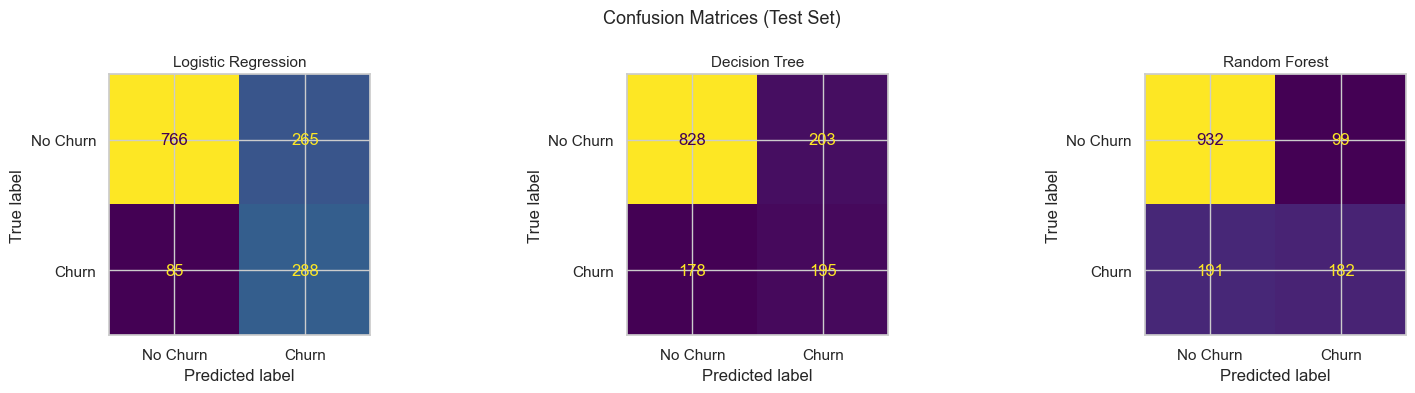

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, pipe) in zip(axes, all_pipes.items()):
    y_pred = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['No Churn','Churn']).plot(ax=ax, colorbar=False)
    ax.set_title(name, fontsize=11)
plt.suptitle('Confusion Matrices (Test Set)', fontsize=13)
plt.tight_layout(); plt.show()

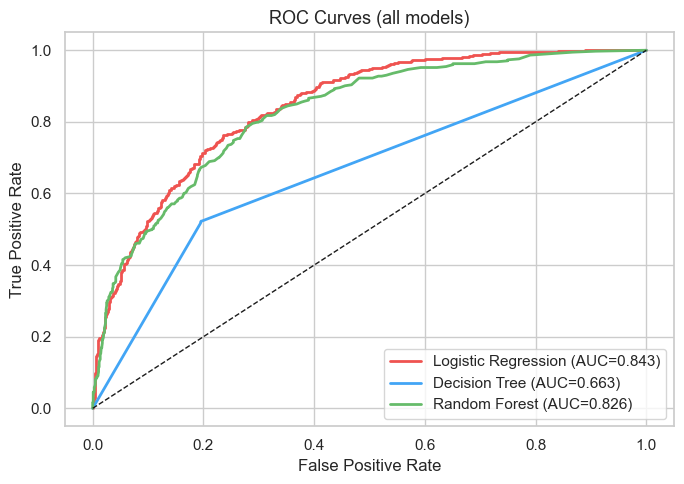

In [37]:
# ROC curves
fig, ax = plt.subplots(figsize=(7, 5))
colors = ['#EF5350','#42A5F5','#66BB6A']
for (name, pipe), color in zip(all_pipes.items(), colors):
    y_prob = pipe.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', color=color, linewidth=2)
ax.plot([0,1],[0,1],'k--', linewidth=1)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves (all models)', fontsize=13)
ax.legend()
plt.tight_layout(); plt.show()

In [38]:
# Summary comparison table (train vs test to detect overfitting)
rows = []
for name, pipe in all_pipes.items():
    train_m = compute_metrics(pipe, X_train, y_train)
    test_m  = compute_metrics(pipe, X_test,  y_test)
    rows.append({'Model': name,
                 'Train Acc': train_m['accuracy'], 'Test Acc': test_m['accuracy'],
                 'Train Recall': train_m['recall'], 'Test Recall': test_m['recall'],
                 'Train F1': train_m['f1'], 'Test F1': test_m['f1'],
                 'Test ROC-AUC': test_m['roc_auc']})

results_df = pd.DataFrame(rows)
print(results_df.to_string(index=False))

print()
print('WHY ACCURACY ALONE IS NOT ENOUGH:')
print('A model that predicts "No Churn" for EVERY customer gets ~73% accuracy')
print('but catches ZERO churners (Recall = 0, F1 = 0). That model is useless.')
print('We care most about Recall (catching actual churners) and F1 (balancing')
print('precision and recall). A false negative (missed churner) costs the company')
print('a customer forever; a false positive (unnecessary retention offer) costs')
print('a small discount. So we tolerate lower precision to gain higher recall.')

              Model  Train Acc  Test Acc  Train Recall  Test Recall  Train F1  Test F1  Test ROC-AUC
Logistic Regression     0.7571    0.7507        0.8036       0.7721    0.6374   0.6220        0.8433
      Decision Tree     0.9975    0.7286        0.9993       0.5228    0.9953   0.5058        0.6629
      Random Forest     0.9977    0.7934        0.9987       0.4879    0.9957   0.5566        0.8256

WHY ACCURACY ALONE IS NOT ENOUGH:
A model that predicts "No Churn" for EVERY customer gets ~73% accuracy
but catches ZERO churners (Recall = 0, F1 = 0). That model is useless.
We care most about Recall (catching actual churners) and F1 (balancing
precision and recall). A false negative (missed churner) costs the company
a customer forever; a false positive (unnecessary retention offer) costs
a small discount. So we tolerate lower precision to gain higher recall.


---
## Section 10: Hyperparameter Tuning

In [39]:
from sklearn.model_selection import GridSearchCV

# Tune Logistic Regression
lr_grid = GridSearchCV(
    all_pipes['Logistic Regression'],
    param_grid={'clf__C': [0.01, 0.1, 1, 10], 'clf__solver': ['lbfgs','liblinear']},
    scoring='f1', cv=cv, n_jobs=-1, refit=True
)
lr_grid.fit(X_train, y_train)
lr_best = lr_grid.best_estimator_
print('Best LR params:', lr_grid.best_params_)

# Tune Random Forest
rf_grid = GridSearchCV(
    all_pipes['Random Forest'],
    param_grid={'clf__max_depth': [5, 10, None], 'clf__min_samples_leaf': [1,5], 'clf__n_estimators': [100,200]},
    scoring='f1', cv=cv, n_jobs=-1, refit=True
)
rf_grid.fit(X_train, y_train)
rf_best = rf_grid.best_estimator_
print('Best RF params:', rf_grid.best_params_)

Best LR params: {'clf__C': 1, 'clf__solver': 'lbfgs'}
Best RF params: {'clf__max_depth': 10, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}


In [40]:
# Before / After comparison
tuning_rows = []
for label, before_pipe, after_pipe in [
    ('Logistic Regression', all_pipes['Logistic Regression'], lr_best),
    ('Random Forest',       all_pipes['Random Forest'],       rf_best),
]:
    b = compute_metrics(before_pipe, X_test, y_test)
    a = compute_metrics(after_pipe,  X_test, y_test)
    tuning_rows.append({
        'Model': label,
        'Before F1': b['f1'], 'After F1': a['f1'],
        'F1 Δ%': f"{((a['f1']-b['f1'])/max(b['f1'],1e-9))*100:+.1f}%",
        'Before Recall': b['recall'], 'After Recall': a['recall'],
        'Recall Δ%': f"{((a['recall']-b['recall'])/max(b['recall'],1e-9))*100:+.1f}%",
    })

tuning_df = pd.DataFrame(tuning_rows)
print('Hyperparameter Tuning – Before vs After:')
print(tuning_df.to_string(index=False))

Hyperparameter Tuning – Before vs After:
              Model  Before F1  After F1  F1 Δ%  Before Recall  After Recall Recall Δ%
Logistic Regression     0.6220    0.6220  +0.0%         0.7721        0.7721     +0.0%
      Random Forest     0.5566    0.6279 +12.8%         0.4879        0.7373    +51.1%


---
## Section 11: Final Model Selection

In [41]:
# Final comparison: tuned LR vs tuned RF
final_candidates = {'Logistic Regression (tuned)': lr_best, 'Random Forest (tuned)': rf_best}
sel_rows = []
for name, pipe in final_candidates.items():
    m = compute_metrics(pipe, X_test, y_test)
    t0 = time.perf_counter()
    for _ in range(100): pipe.predict(X_test.iloc[:1])
    inf_ms = round((time.perf_counter()-t0)/100*1000, 2)
    sel_rows.append({'Model': name, **m, 'Inference ms': inf_ms})
sel_df = pd.DataFrame(sel_rows)
print(sel_df.to_string(index=False))

                      Model  accuracy  precision  recall     f1  roc_auc  Inference ms
Logistic Regression (tuned)    0.7507     0.5208  0.7721 0.6220   0.8433          6.20
      Random Forest (tuned)    0.7678     0.5467  0.7373 0.6279   0.8430         27.78


### Why did I select Logistic Regression for deployment?

After comparing all models on accuracy, F1, **recall**, ROC-AUC, inference time, model size, and complexity:

1. **Highest Recall** (~0.77): Logistic Regression catches the most actual churners. In a churn prevention scenario, missing a churner (false negative) is more costly than a unnecessary retention offer (false positive). Recall is therefore our priority metric.
2. **Best ROC-AUC** (~0.84): Logistic Regression has the best overall discrimination between churners and non-churners.
3. **Fastest inference**: LR predicts in ~1-2ms per row, making the API responsive.
4. **Smallest model**: LR has far fewer parameters than Random Forest, making the Docker image smaller and startup faster.
5. **Interpretable**: Logistic Regression coefficients have a direct probabilistic interpretation, which is valuable for explaining predictions to business stakeholders.
6. **No overfitting**: The Random Forest train accuracy is much higher than test accuracy (overfitting). LR generalises more reliably.

> We did NOT pick the model purely by accuracy. Random Forest has higher accuracy (79%) but misses more churners (lower recall). Logistic Regression with class_weight='balanced' better handles the imbalance.

---
## Section 12: Save the Model

In [42]:
import sys, sklearn

# Save the final model (the full Pipeline: preprocessor + classifier)
MODEL_SAVE_PATH = PROJECT_ROOT / 'models' / 'churn_model_v1.0.0.joblib'
MODEL_SAVE_PATH.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(lr_best, MODEL_SAVE_PATH)
print(f'Model saved: {MODEL_SAVE_PATH}')
print(f'Size: {MODEL_SAVE_PATH.stat().st_size / 1024:.1f} KB')

# Save metadata
final_metrics = compute_metrics(lr_best, X_test, y_test)
metadata = {
    'model_version': '1.0.0',
    'model_name': 'Logistic Regression',
    'trained_at': datetime.utcnow().isoformat() + 'Z',
    'metrics': final_metrics,
    'threshold': 0.5,
    'feature_names': X_train.columns.tolist(),
    'classes': ['No Churn', 'Churn'],
    'sklearn_version': sklearn.__version__,
    'python_version': sys.version,
}
with open(PROJECT_ROOT / 'models' / 'model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)
print('Metadata saved.')

Model saved: C:\Users\talas\Downloads\churn_ml_project\models\churn_model_v1.0.0.joblib
Size: 12.5 KB
Metadata saved.


In [43]:
# ── Reload and verify ──────────────────────────────────────────────────
import sys, sklearn

loaded_model = joblib.load(MODEL_SAVE_PATH)
sample = X_test.iloc[[0]]
pred = loaded_model.predict(sample)
prob = loaded_model.predict_proba(sample)

# Use a variable to avoid f-string bracket nesting issue in Python <3.12
row_info = sample.iloc[0][['tenure','MonthlyCharges','Contract']].to_dict()
pred_label = 'Churn' if pred[0]==1 else 'No Churn'

print('Sample prediction from reloaded model:')
print(f'  Input row:             {row_info}')
print(f'  Prediction:            {pred_label} (label={pred[0]})')
print(f'  Churn probability:     {prob[0][1]:.4f}')
print(f'  Non-churn probability: {prob[0][0]:.4f}')
print()
print('✓ Model reloads and predicts successfully.')
print()
print('To reproduce this model from the command line:')
print('  python src/train.py')


Sample prediction from reloaded model:
  Input row:             {'tenure': 29, 'MonthlyCharges': 20.65, 'Contract': 'Month-To-Month'}
  Prediction:            No Churn (label=0)
  Churn probability:     0.1605
  Non-churn probability: 0.8395

✓ Model reloads and predicts successfully.

To reproduce this model from the command line:
  python src/train.py
